<a href="https://colab.research.google.com/github/Mahmoud4Younis/my-/blob/main/Who_Gets_Hospitalized_with_Flu_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Who Gets Hospitalized with Flu?
### Analyzing 18 Seasons of CDC Influenza Hospitalization Data (2009–2026) by Age, Sex, Race and Virus Type

## Project Description
This project explores real influenza hospitalization data from the CDC's **Influenza Hospitalization Surveillance Network (FluSurv-NET)**. The network tracks lab-confirmed flu hospitalizations across selected counties in about 13 US states. The dataset covers **18 flu seasons (2009–10 to 2026–27)** and reports weekly and cumulative hospitalization rates per 100,000 people, broken down by **age group, sex, race/ethnicity, and virus type**.

**Workflow:**
1. **Data cleaning:** handle the raw CDC file format, missing values, and "Overall" summary rows.
2. **Exploratory data analysis:** compare hospitalization rates across age groups, sex, race/ethnicity, and virus types.
3. **Trend analysis:** compare seasons, find peak weeks, and spot unusually severe or mild years.
4. **Visualization:** use charts to show differences between groups and patterns over time.
5. **Insights and recommendations:** turn findings into practical suggestions for vaccination priorities and hospital preparation.

**Data source:** [CDC FluView Interactive – FluSurv-NET](https://gis.cdc.gov/GRASP/Fluview/FluHospRates.html)

> **Note:** The data is aggregated by group (not one row per patient) and covers selected areas, not the whole US.

---

## Objectives
1. **Identify high-risk groups:** find out which age groups, sexes and races/ethnicities have the highest flu hospitalization rates.
2. **Compare flu seasons:** measure how severe each season was (2009–10 to 2026–27) and find the worst and mildest seasons.
3. **Find seasonal patterns:** find when flu hospitalizations usually start rising, peak, and decline during the year.
4. **Compare virus types:** compare hospitalization rates caused by Influenza A vs. B, and by the A(H1N1) and A(H3N2) subtypes.
5. **Study the COVID-19 effect:** check how flu hospitalizations changed during the 2020–21 and 2021–22 seasons.
6. **Give recommendations:** turn the findings into practical suggestions for vaccination priorities and hospital planning.

---

## Dataset Features
**Size:** 28,758 rows × 16 columns

| Feature | Type | Description |
|---|---|---|
| `catchment` | Categorical | Area the data covers |
| `network` | Categorical | Surveillance network |
| `season` | Categorical | Flu season |
| `year` | Numeric (int) | Calendar year of the week |
| `week` | Numeric (int) | Week number of the year |
| `age_group` | Categorical | Age group |
| `sex` | Categorical | Sex |
| `race` | Categorical | Race/ethnicity |
| `virus_type` | Categorical | Flu virus type |
| `cumulative_rate` | Numeric (float) | Total hospitalizations per 100k so far in the season |
| `weekly_rate` | Numeric (float) | Hospitalizations per 100k in that week |
| `age_adjusted_cumulative_rate` | Numeric (float) | Cumulative rate adjusted for age |
| `age_adjusted_weekly_rate` | Numeric (float) | Weekly rate adjusted for age |
| `lower` | Numeric (float) | Lower nowcast estimate for recent weeks |
| `median` | Numeric (float) | Middle nowcast estimate for recent weeks |
| `upper` | Numeric (float) | Upper nowcast estimate for recent weeks |


In [53]:
#download data from drive
import gdown
file_id = "1x60gn8dXp3ULtVdznpxYOAkLGhM2J2Wb"
destination = "data.csv"   # name you want to save as

gdown.download(f"https://drive.google.com/uc?id={file_id}", destination, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1x60gn8dXp3ULtVdznpxYOAkLGhM2J2Wb
To: /content/data.csv
100%|██████████| 3.25M/3.25M [00:00<00:00, 111MB/s]


'data.csv'

In [54]:
#import libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


#Read Data
original_df = pd.read_csv('data.csv')
df = original_df.copy()
df.head()

,CATCHMENT,NETWORK,YEAR,YEAR.1,WEEK,AGE CATEGORY,SEX CATEGORY,RACE CATEGORY,VIRUS TYPE CATEGORY,CUMULATIVE RATE,WEEKLY RATE,AGE ADJUSTED CUMULATIVE RATE,AGE ADJUSTED WEEKLY RATE,LOWER,MEDIAN,UPPER
0,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,White,Overall,4.3,1.7,2.58,0.97,NaN,NaN,NaN
1,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Black,Overall,11.6,3.6,7.68,2.18,NaN,NaN,NaN
2,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Hispanic/Latino,Overall,12.8,4.8,7.50,2.73,NaN,NaN,NaN
3,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,Asian/Pacific Islander,Overall,3.5,1.3,2.23,0.62,NaN,NaN,NaN
4,Entire Network,FluSurv-NET,2009-10,2009,40,Overall,Overall,American Indian/Alaska Native,Overall,10.4,4.3,5.52,0.40,NaN,NaN,NaN


In [55]:
df.tail()

,CATCHMENT,NETWORK,YEAR,YEAR.1,WEEK,AGE CATEGORY,SEX CATEGORY,RACE CATEGORY,VIRUS TYPE CATEGORY,CUMULATIVE RATE,WEEKLY RATE,AGE ADJUSTED CUMULATIVE RATE,AGE ADJUSTED WEEKLY RATE,LOWER,MEDIAN,UPPER
28753,Entire Network,FluSurv-NET,2026-27,2027,35,>= 18,Overall,Overall,Overall,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28754,Entire Network,FluSurv-NET,2026-27,2027,36,>= 18,Overall,Overall,Overall,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28755,Entire Network,FluSurv-NET,2026-27,2027,37,>= 18,Overall,Overall,Overall,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28756,Entire Network,FluSurv-NET,2026-27,2027,38,>= 18,Overall,Overall,Overall,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28757,Entire Network,FluSurv-NET,2026-27,2027,39,>= 18,Overall,Overall,Overall,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [56]:
df.shape

(28758, 16)

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28758 entries, 0 to 28757
Data columns (total 16 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   CATCHMENT                     28758 non-null  object 
 1   NETWORK                       28758 non-null  object 
 2   YEAR                          28758 non-null  object 
 3   YEAR.1                        28758 non-null  int64  
 4   WEEK                          28758 non-null  int64  
 5   AGE CATEGORY                  28758 non-null  object 
 6   SEX CATEGORY                  28758 non-null  object 
 7   RACE CATEGORY                 28758 non-null  object 
 8   VIRUS TYPE CATEGORY           28758 non-null  object 
 9   CUMULATIVE RATE               25773 non-null  float64
 10  WEEKLY RATE                   25680 non-null  float64
 11  AGE ADJUSTED CUMULATIVE RATE  12840 non-null  float64
 12  AGE ADJUSTED WEEKLY RATE      12840 non-null  float64
 13  L

In [58]:
df.columns

Index(['CATCHMENT', 'NETWORK', 'YEAR', 'YEAR.1', 'WEEK', 'AGE CATEGORY',
       'SEX CATEGORY', 'RACE CATEGORY', 'VIRUS TYPE CATEGORY',
       'CUMULATIVE RATE', 'WEEKLY RATE', 'AGE ADJUSTED CUMULATIVE RATE',
       'AGE ADJUSTED WEEKLY RATE', 'LOWER', 'MEDIAN', 'UPPER'],
      dtype='object')

In [59]:
df.CATCHMENT.unique()

array(['Entire Network'], dtype=object)

In [60]:
#Note :CATCHMENT has one single Value we can Drop

In [61]:
df.drop(columns=["CATCHMENT"],inplace=True)

In [62]:
df.columns

Index(['NETWORK', 'YEAR', 'YEAR.1', 'WEEK', 'AGE CATEGORY', 'SEX CATEGORY',
       'RACE CATEGORY', 'VIRUS TYPE CATEGORY', 'CUMULATIVE RATE',
       'WEEKLY RATE', 'AGE ADJUSTED CUMULATIVE RATE',
       'AGE ADJUSTED WEEKLY RATE', 'LOWER', 'MEDIAN', 'UPPER'],
      dtype='object')

In [63]:
df.NETWORK.unique()

array(['FluSurv-NET'], dtype=object)

In [64]:
#Note : NETWORK has one single Value we can Drop

In [65]:
df.drop(columns=["NETWORK"],inplace=True)

In [66]:
df.columns

Index(['YEAR', 'YEAR.1', 'WEEK', 'AGE CATEGORY', 'SEX CATEGORY',
       'RACE CATEGORY', 'VIRUS TYPE CATEGORY', 'CUMULATIVE RATE',
       'WEEKLY RATE', 'AGE ADJUSTED CUMULATIVE RATE',
       'AGE ADJUSTED WEEKLY RATE', 'LOWER', 'MEDIAN', 'UPPER'],
      dtype='object')

In [67]:
df.YEAR.head()

,YEAR
0,2009-10
1,2009-10
2,2009-10
3,2009-10
4,2009-10


In [68]:
df["YEAR.1"].head()

,YEAR.1
0,2009
1,2009
2,2009
3,2009
4,2009


In [69]:
#Note : YEAR & YEAR.1 has the same Values so we can Drop one of it (YEAR.1)

In [70]:
df.drop(columns=["YEAR.1"],inplace=True)

In [71]:
df.columns

Index(['YEAR', 'WEEK', 'AGE CATEGORY', 'SEX CATEGORY', 'RACE CATEGORY',
       'VIRUS TYPE CATEGORY', 'CUMULATIVE RATE', 'WEEKLY RATE',
       'AGE ADJUSTED CUMULATIVE RATE', 'AGE ADJUSTED WEEKLY RATE', 'LOWER',
       'MEDIAN', 'UPPER'],
      dtype='object')

In [72]:
df.WEEK.unique()

array([40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52,  1,  2,  3,  4,
        5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 53, 18, 19, 20,
       21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37,
       38, 39])

In [73]:
len(df.WEEK.unique())

53

In [74]:
df.columns

Index(['YEAR', 'WEEK', 'AGE CATEGORY', 'SEX CATEGORY', 'RACE CATEGORY',
       'VIRUS TYPE CATEGORY', 'CUMULATIVE RATE', 'WEEKLY RATE',
       'AGE ADJUSTED CUMULATIVE RATE', 'AGE ADJUSTED WEEKLY RATE', 'LOWER',
       'MEDIAN', 'UPPER'],
      dtype='object')

In [75]:
df["AGE CATEGORY"].unique()

array(['Overall', '0-4 yr', '5-17 yr', '18-49 yr', '50-64 yr', '>= 65 yr',
       '65-74 yr', '75-84 yr', '>= 85', '18-29 yr', '30-39 yr',
       '40-49 yr', '0-< 1 yr', '1-4 yr', '>= 75', '5-11  yr', '12-17 yr',
       '< 18', '>= 18'], dtype=object)

In [76]:
df.head(10)

,YEAR,WEEK,AGE CATEGORY,SEX CATEGORY,RACE CATEGORY,VIRUS TYPE CATEGORY,CUMULATIVE RATE,WEEKLY RATE,AGE ADJUSTED CUMULATIVE RATE,AGE ADJUSTED WEEKLY RATE,LOWER,MEDIAN,UPPER
0,2009-10,40,Overall,Overall,White,Overall,4.3,1.7,2.58,0.97,NaN,NaN,NaN
1,2009-10,40,Overall,Overall,Black,Overall,11.6,3.6,7.68,2.18,NaN,NaN,NaN
2,2009-10,40,Overall,Overall,Hispanic/Latino,Overall,12.8,4.8,7.50,2.73,NaN,NaN,NaN
3,2009-10,40,Overall,Overall,Asian/Pacific Islander,Overall,3.5,1.3,2.23,0.62,NaN,NaN,NaN
4,2009-10,40,Overall,Overall,American Indian/Alaska Native,Overall,10.4,4.3,5.52,0.40,NaN,NaN,NaN
5,2009-10,40,Overall,Male,Overall,Overall,6.4,2.6,NaN,NaN,NaN,NaN,NaN
6,2009-10,40,Overall,Female,Overall,Overall,8.3,3.0,NaN,NaN,NaN,NaN,NaN
7,2009-10,40,Overall,Overall,Overall,Influenza A,7.2,2.8,4.08,1.40,NaN,NaN,NaN
8,2009-10,40,Overall,Overall,Overall,Overall,7.4,2.8,4.08,1.40,NaN,NaN,NaN
9,2009-10,40,Overall,Overall,Overall,Influenza B,0.0,0.0,4.08,1.40,NaN,NaN,NaN


In [77]:
#NOTE:We noticed that AGE CATEGORY contains overlapping age groups and Overall rows, so we will select only the broad age groups to avoid overlapping comparisons.

In [78]:
age_groups = [
    '0-4 yr',
    '5-17 yr',
    '18-49 yr',
    '50-64 yr',
    '>= 65 yr'
]

df_age = df[
    df['AGE CATEGORY'].isin(age_groups) &
    (df['SEX CATEGORY'] == 'Overall') &
    (df['RACE CATEGORY'] == 'Overall') &
    (df['VIRUS TYPE CATEGORY'] == 'Overall')
].copy()

In [79]:
df_age.head(10)

,YEAR,WEEK,AGE CATEGORY,SEX CATEGORY,RACE CATEGORY,VIRUS TYPE CATEGORY,CUMULATIVE RATE,WEEKLY RATE,AGE ADJUSTED CUMULATIVE RATE,AGE ADJUSTED WEEKLY RATE,LOWER,MEDIAN,UPPER
302,2009-10,40,0-4 yr,Overall,Overall,Overall,18.1,7.2,4.08,1.40,NaN,NaN,NaN
303,2009-10,41,0-4 yr,Overall,Overall,Overall,28.3,10.2,6.47,2.40,NaN,NaN,NaN
308,2009-10,42,0-4 yr,Overall,Overall,Overall,39.1,10.8,9.58,3.10,NaN,NaN,NaN
309,2009-10,43,0-4 yr,Overall,Overall,Overall,47.3,8.2,13.08,3.50,NaN,NaN,NaN
314,2009-10,44,0-4 yr,Overall,Overall,Overall,53.3,6.0,16.18,3.10,NaN,NaN,NaN
315,2009-10,45,0-4 yr,Overall,Overall,Overall,57.5,4.2,18.60,2.42,NaN,NaN,NaN
320,2009-10,46,0-4 yr,Overall,Overall,Overall,60.1,2.6,20.18,1.58,NaN,NaN,NaN
321,2009-10,47,0-4 yr,Overall,Overall,Overall,61.6,1.5,21.33,1.15,NaN,NaN,NaN
326,2009-10,48,0-4 yr,Overall,Overall,Overall,62.9,1.3,22.01,0.68,NaN,NaN,NaN
327,2009-10,49,0-4 yr,Overall,Overall,Overall,64.1,1.3,22.46,0.45,NaN,NaN,NaN


In [80]:
df_age.shape

(3075, 13)

In [81]:
df["RACE CATEGORY"].unique()

array(['White', 'Black', 'Hispanic/Latino', 'Asian/Pacific Islander',
       'American Indian/Alaska Native', 'Overall'], dtype=object)

In [111]:
df.groupby("RACE CATEGORY")["AGE ADJUSTED CUMULATIVE RATE"].mean().sort_values(ascending=False)

,AGE ADJUSTED CUMULATIVE RATE
RACE CATEGORY,
Black,49.347341
American Indian/Alaska Native,40.094326
Hispanic/Latino,29.725094
Overall,27.235628
White,25.333034
Asian/Pacific Islander,17.612228


In [ ]:
# NOTE: Black had the highest average age-adjusted cumulative hospitalization rate, while Asian/Pacific Islander had the lowest

In [83]:
df['VIRUS TYPE CATEGORY'].unique()

array(['Overall', 'Influenza A', 'Influenza B', 'A(H1N1)pdm09', 'A(H3N2)'],
      dtype=object)

In [84]:
#NOTE:The VIRUS TYPE CATEGORY values are normal;and after researching these categories, I found that A(H1N1)pdm09 and A(H3N2) are subtypes of Influenza A, not separate main virus types.

In [85]:
df.columns

Index(['YEAR', 'WEEK', 'AGE CATEGORY', 'SEX CATEGORY', 'RACE CATEGORY',
       'VIRUS TYPE CATEGORY', 'CUMULATIVE RATE', 'WEEKLY RATE',
       'AGE ADJUSTED CUMULATIVE RATE', 'AGE ADJUSTED WEEKLY RATE', 'LOWER',
       'MEDIAN', 'UPPER'],
      dtype='object')

In [86]:
df['CUMULATIVE RATE'].unique()

array([ 4.3, 11.6, 12.8, ..., 94.8, 98.3, 99.4])

In [87]:
df['CUMULATIVE RATE']

,CUMULATIVE RATE
0,4.3
1,11.6
2,12.8
3,3.5
4,10.4
...,...
28753,NaN
28754,NaN
28755,NaN
28756,NaN


In [88]:
len(df['CUMULATIVE RATE'].unique())


6867

In [89]:
df['CUMULATIVE RATE'].isna().sum()

np.int64(2985)

In [90]:
df['CUMULATIVE RATE'].duplicated().sum()

np.int64(21891)

In [91]:
df.shape

(28758, 13)

In [92]:
#NOTE : We observed 2,985 missing values (NaN) and 6,867 unique values in `CUMULATIVE RATE`, with 21,891 repeated values in this column; the dataset contains 28,758 rows and 13 columns. Repeated values do not necessarily indicate duplicate rows.

In [93]:
mask = (
    (df['AGE CATEGORY'] == 'Overall') &
    (df['SEX CATEGORY'] == 'Overall') &
    (df['RACE CATEGORY'] == 'Overall') &
    (df['VIRUS TYPE CATEGORY'] == 'Overall')
)

df_overall = df[mask]
df_overall.groupby('YEAR')['CUMULATIVE RATE'].mean()

,CUMULATIVE RATE
YEAR,
2009-10,25.373333
2010-11,8.696667
2011-12,2.130000
2012-13,22.006667
2013-14,16.413333
2014-15,33.287097
2015-16,8.766667
2016-17,24.406667
2017-18,46.800000


In [94]:
# NOTE: The 2025–2026 season has the highest mean cumulative rate, while the 2020–2021 season has the lowest

In [95]:
df.columns

Index(['YEAR', 'WEEK', 'AGE CATEGORY', 'SEX CATEGORY', 'RACE CATEGORY',
       'VIRUS TYPE CATEGORY', 'CUMULATIVE RATE', 'WEEKLY RATE',
       'AGE ADJUSTED CUMULATIVE RATE', 'AGE ADJUSTED WEEKLY RATE', 'LOWER',
       'MEDIAN', 'UPPER'],
      dtype='object')

In [96]:
df['WEEKLY RATE'].unique()

array([ 1.7,  3.6,  4.8, ..., 28.1, 61.6, 71.2])

In [97]:
len(df['WEEKLY RATE'].unique())

4662

In [98]:
df['WEEKLY RATE'].isna().sum()

np.int64(3078)

In [99]:
df['WEEKLY RATE'].duplicated().sum()

np.int64(24096)

In [113]:

mask = (
    (df['AGE CATEGORY'] == 'Overall') &
    (df['SEX CATEGORY'] == 'Overall') &
    (df['RACE CATEGORY'] == 'Overall') &
    (df['VIRUS TYPE CATEGORY'] == 'Overall')
)

df_overall = df[mask].dropna(subset=['WEEKLY RATE'])

peak_weeks = df_overall.loc[
    df_overall.groupby('YEAR')['WEEKLY RATE'].idxmax(),
    ['YEAR', 'WEEK', 'WEEKLY RATE']
].sort_values('YEAR')

display(peak_weeks)


,YEAR,WEEK,WEEKLY RATE
28,2009-10,42,4.0
1390,2010-11,8,2.1
2917,2011-12,11,1.1
4297,2012-13,1,5.4
5797,2013-14,1,3.9
7294,2014-15,52,9.0
8964,2015-16,10,4.2
10433,2016-17,8,5.4
11847,2017-18,1,10.2
13467,2018-19,11,5.5


In [ ]:
# NOTE: Across the 17 seasons with available data, the peak weekly hospitalization rate occurred during weeks 1–16 in 11 seasons and weeks 40–52 in 6 seasons. No season's peak occurred during weeks 17–39

In [100]:
df['AGE ADJUSTED CUMULATIVE RATE'].unique()

array([2.58, 7.68, 7.5 , ..., 1.92, 2.61, 1.76])

In [114]:
df["AGE ADJUSTED WEEKLY RATE"].unique()

array([9.700e-01, 2.180e+00, 2.730e+00, 6.200e-01, 4.000e-01,       nan,
       1.400e+00, 2.400e+00, 4.310e+00, 1.370e+00, 4.880e+00, 3.390e+00,
       1.800e+00, 2.580e+00, 4.780e+00, 4.660e+00, 9.500e+00, 3.100e+00,
       3.500e+00, 5.760e+00, 2.000e+00, 4.980e+00, 4.840e+00, 3.190e+00,
       2.940e+00, 4.400e+00, 3.410e+00, 1.630e+00, 4.530e+00, 2.420e+00,
       5.910e+00, 1.180e+00, 2.910e+00, 3.650e+00, 2.120e+00, 1.520e+00,
       2.380e+00, 1.490e+00, 1.340e+00, 1.310e+00, 1.580e+00, 1.150e+00,
       8.700e-01, 7.200e-01, 1.740e+00, 2.020e+00, 9.800e-01, 5.300e-01,
       1.040e+00, 3.400e-01, 1.420e+00, 6.800e-01, 4.500e-01, 3.800e-01,
       5.700e-01, 6.600e-01, 2.900e-01, 2.600e-01, 3.600e-01, 0.000e+00,
       3.100e-01, 4.400e-01, 3.700e-01, 2.100e-01, 1.800e-01, 5.600e-01,
       3.900e-01, 1.700e-01, 2.400e-01, 2.300e-01, 1.900e-01, 1.400e-01,
       2.000e-01, 2.200e-01, 3.000e-01, 1.000e-01, 3.300e-01, 7.000e-02,
       1.100e+00, 1.500e-01, 2.700e-01, 9.000e-02, 

In [116]:
df['LOWER'].unique()

array([ nan, 0.19, 0.31, 0.35, 0.48, 0.79, 0.92, 1.13, 1.49])

In [117]:
df['MEDIAN'].unique()

array([ nan, 0.19, 0.31, 0.35, 0.49, 0.81, 0.95, 1.24, 1.75])

In [119]:
df['UPPER'].unique()

array([ nan, 0.19, 0.31, 0.36, 0.5 , 0.83, 0.98, 1.3 , 2.02])

In [120]:
df['UPPER'].isna().sum()

np.int64(28750)

In [121]:
df['MEDIAN'].isna().sum()

np.int64(28750)

In [122]:
df['LOWER'].isna().sum()

np.int64(28750)

In [ ]:
# NOTE: The values in `LOWER`, `MEDIAN`, and `UPPER` are very close, indicating a narrow estimation range. However, each column contains 28,750 missing values out of 28,758 rows, leaving only 8 non-missing records.

In [123]:
# Prepare the data
age_groups = ['0-4 yr', '5-17 yr', '18-49 yr', '50-64 yr', '>= 65 yr']

overall_mask = (
    (df['AGE CATEGORY'] == 'Overall') &
    (df['SEX CATEGORY'] == 'Overall') &
    (df['RACE CATEGORY'] == 'Overall') &
    (df['VIRUS TYPE CATEGORY'] == 'Overall')
)

df_overall = df.loc[overall_mask].copy()
df_weekly_overall = df_overall.dropna(subset=['WEEKLY RATE']).copy()

df_age_eda = df[
    df['AGE CATEGORY'].isin(age_groups) &
    (df['SEX CATEGORY'] == 'Overall') &
    (df['RACE CATEGORY'] == 'Overall') &
    (df['VIRUS TYPE CATEGORY'] == 'Overall')
].dropna(subset=['WEEKLY RATE']).copy()

df_virus_eda = df[
    (df['AGE CATEGORY'] == 'Overall') &
    (df['SEX CATEGORY'] == 'Overall') &
    (df['RACE CATEGORY'] == 'Overall') &
    (df['VIRUS TYPE CATEGORY'].isin(['Influenza A', 'Influenza B']))
].dropna(subset=['WEEKLY RATE']).copy()

df_race_eda = df[
    (df['AGE CATEGORY'] == 'Overall') &
    (df['SEX CATEGORY'] == 'Overall') &
    (df['RACE CATEGORY'] != 'Overall') &
    (df['VIRUS TYPE CATEGORY'] == 'Overall')
].dropna(subset=['AGE ADJUSTED CUMULATIVE RATE']).copy()


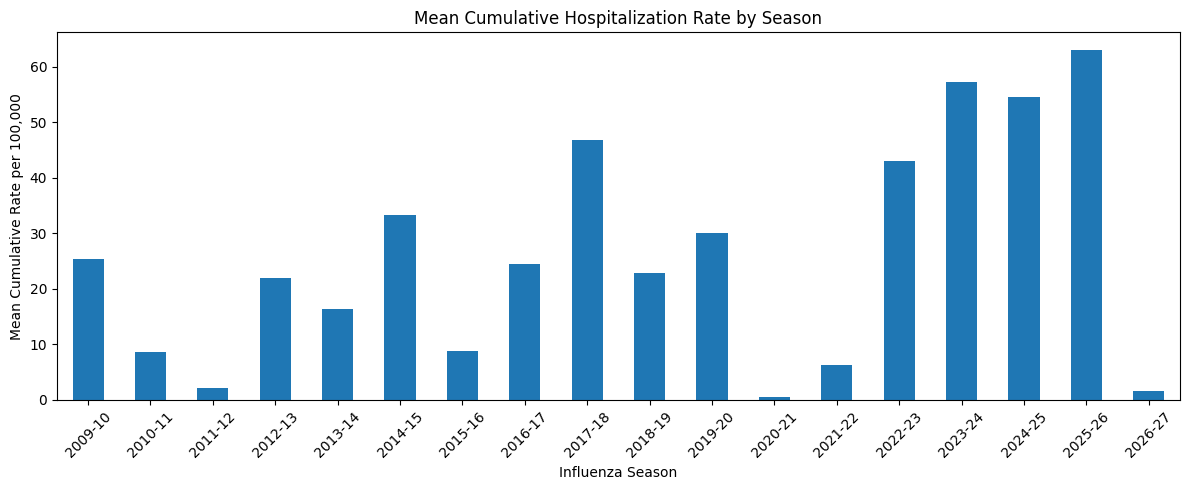

In [124]:
season_mean = df_overall.groupby('YEAR')['CUMULATIVE RATE'].mean()

plt.figure(figsize=(12, 5))
season_mean.plot(kind='bar')

plt.title('Mean Cumulative Hospitalization Rate by Season')
plt.xlabel('Influenza Season')
plt.ylabel('Mean Cumulative Rate per 100,000')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

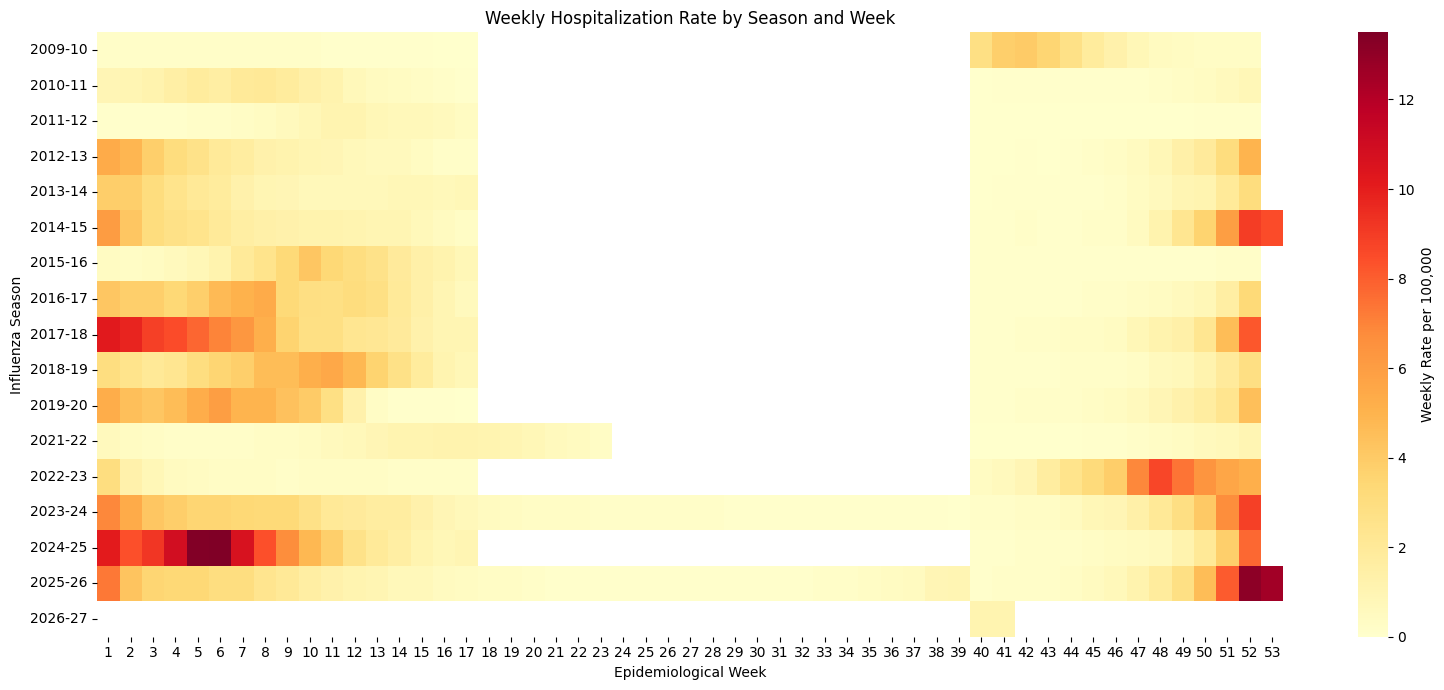

In [125]:
weekly_pivot = df_overall.pivot_table(
    index='YEAR',
    columns='WEEK',
    values='WEEKLY RATE',
    aggfunc='mean'
)

plt.figure(figsize=(16, 7))

sns.heatmap(
    weekly_pivot,
    cmap='YlOrRd',
    cbar_kws={'label': 'Weekly Rate per 100,000'}
)

plt.title('Weekly Hospitalization Rate by Season and Week')
plt.xlabel('Epidemiological Week')
plt.ylabel('Influenza Season')
plt.tight_layout()
plt.show()

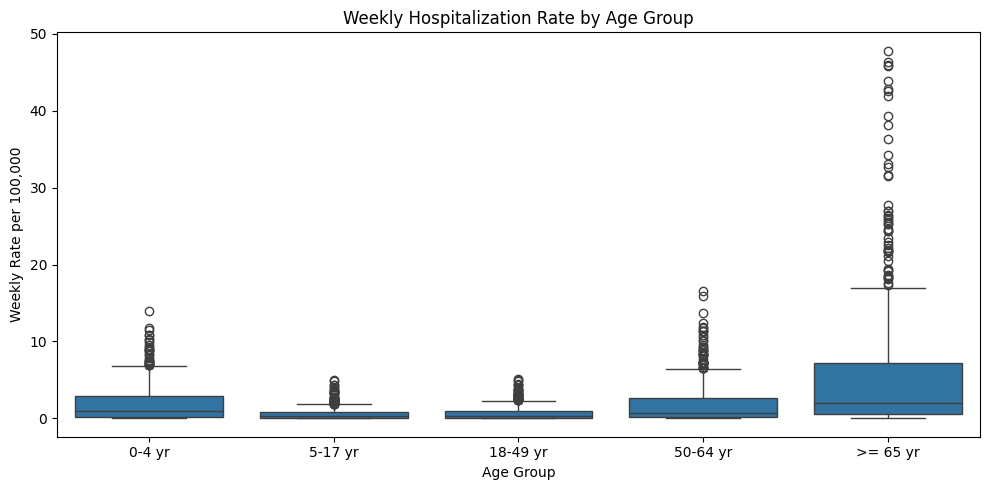

In [126]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_age_eda,
    x='AGE CATEGORY',
    y='WEEKLY RATE',
    order=age_groups
)

plt.title('Weekly Hospitalization Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Weekly Rate per 100,000')
plt.tight_layout()
plt.show()

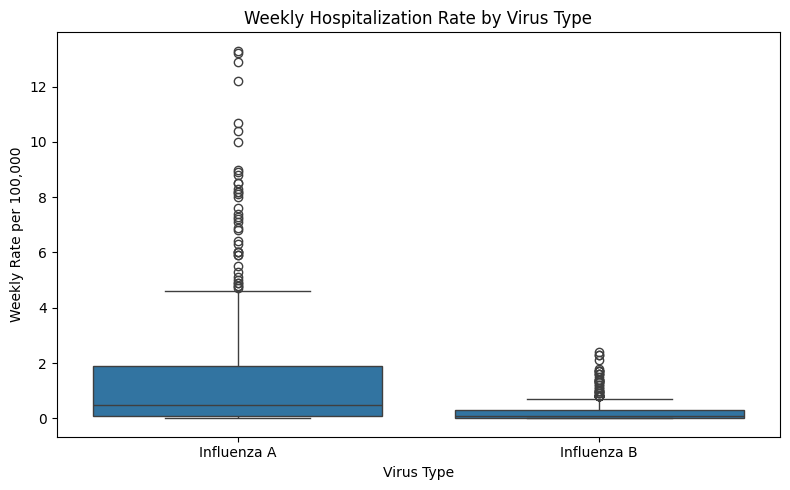

In [127]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_virus_eda,
    x='VIRUS TYPE CATEGORY',
    y='WEEKLY RATE',
    order=['Influenza A', 'Influenza B']
)

plt.title('Weekly Hospitalization Rate by Virus Type')
plt.xlabel('Virus Type')
plt.ylabel('Weekly Rate per 100,000')
plt.tight_layout()
plt.show()

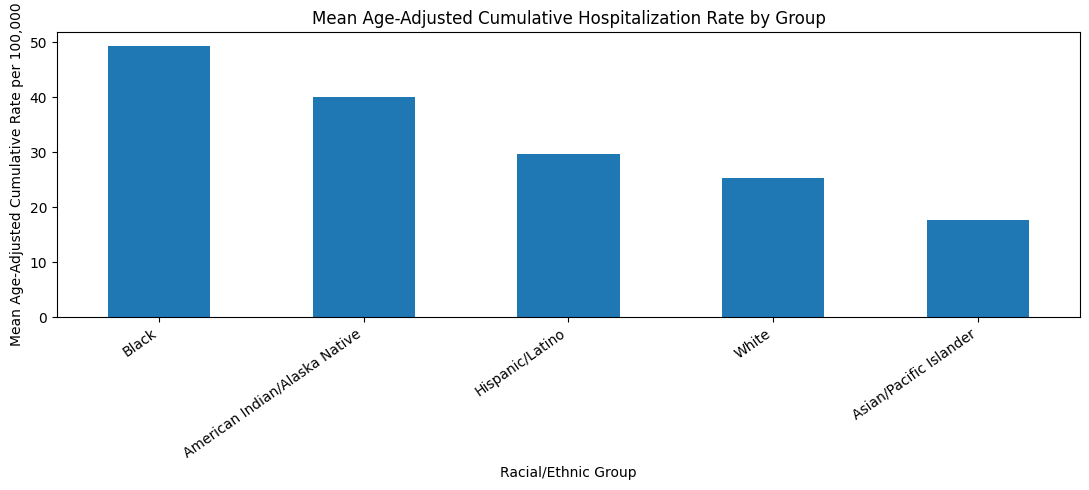

In [128]:
race_mean = (
    df_race_eda.groupby('RACE CATEGORY')['AGE ADJUSTED CUMULATIVE RATE']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 5))
race_mean.plot(kind='bar')

plt.title('Mean Age-Adjusted Cumulative Hospitalization Rate by Group')
plt.xlabel('Racial/Ethnic Group')
plt.ylabel('Mean Age-Adjusted Cumulative Rate per 100,000')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()